# 04 · Is XGBoost enough? Comparing models

**Question:** do LightGBM, CatBoost, a plain logistic regression or an ensemble do better than XGBoost, and
does anything beat the one-line mean-reversion rule by a margin worth believing?

All numbers are on the same held-out years (2019 onwards) and come from `python -m crimebase train`.
Intervals resample whole state-year groups, and differences are tested pairwise on the same resamples.

In [1]:
import numpy as np
import pandas as pd

from crimebase import viz
from crimebase.config import load_config

cfg = load_config()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_colwidth = 80
pd.options.display.width = 140

import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice from optuna, harmless

from crimebase.evaluate import CLASS_NAMES
from crimebase.experiment import final_fit
from crimebase.explain import contributions, importance, signed_effect
from crimebase.features import FEATURES
from crimebase.models import DEFAULTS, fit
from crimebase.pipeline import load_matrix
from crimebase.report import paired_table, scores_table, tuning_table
from crimebase.results import load_comparison, scores_by_year
from crimebase.splits import dev_mask, holdout_mask, train_mask, val_mask

target = "y_trend"
m = load_matrix(cfg)
saved = load_comparison(cfg, target)  # written by `python -m crimebase train`
X, y = m[FEATURES], m[target]
tr, va, dev, te = (f(m, cfg.split, target) for f in (train_mask, val_mask, dev_mask, holdout_mask))

from crimebase.results import recompute_scores

extra = recompute_scores(saved, m, cfg)  # accuracy, macro precision and recall for every entry

## 1. Everything on one scale

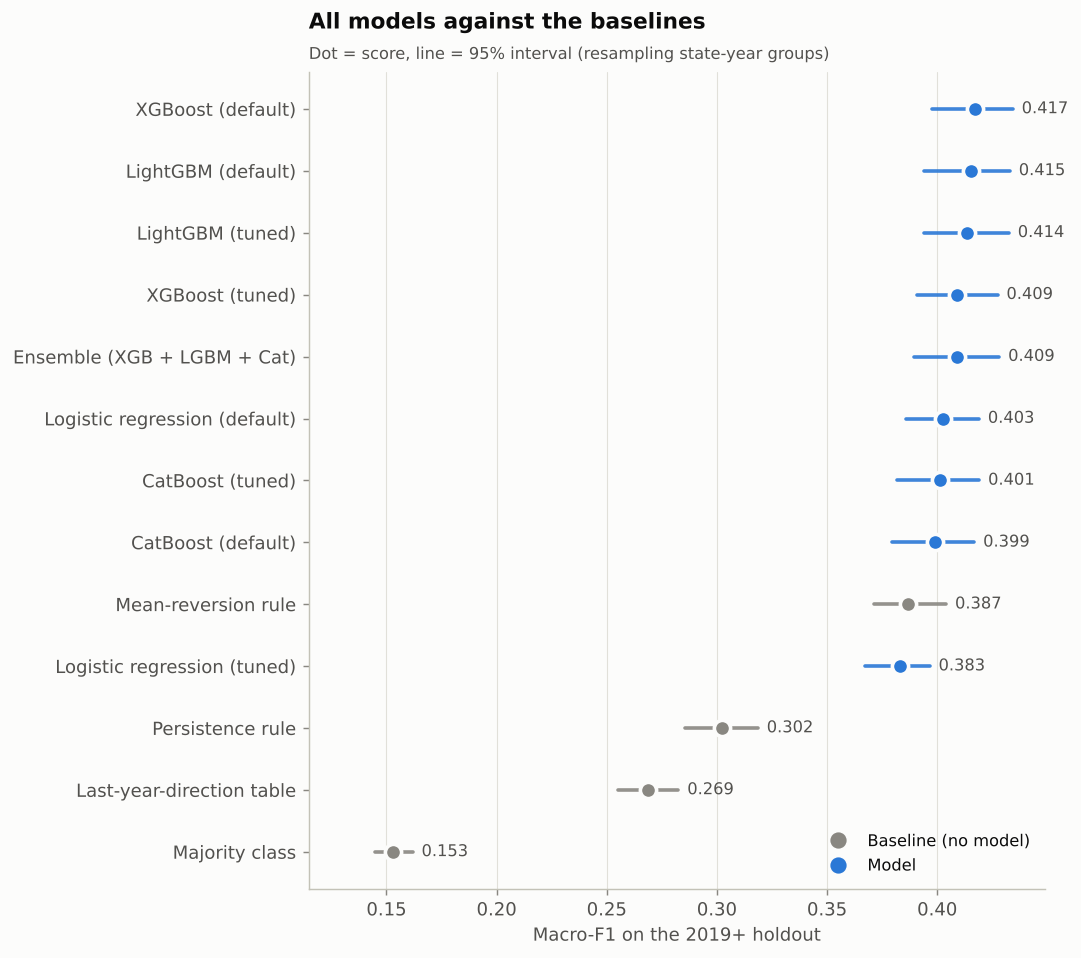

,Accuracy,Precision (macro),Recall (macro),F1 (macro) [95% CI],ROC-AUC [95% CI],Log loss,Trees
Model,,,,,,,
Majority class,0.298,0.099,0.333,"0.153 [0.145, 0.162]","0.500 [0.500, 0.500]",1.107,
Persistence rule,0.316,0.304,0.318,"0.302 [0.285, 0.319]",n/a,n/a,
Mean-reversion rule,0.394,0.412,0.403,"0.387 [0.371, 0.404]",n/a,n/a,
Last-year-direction table,0.378,0.252,0.353,"0.269 [0.255, 0.283]","0.560 [0.549, 0.572]",1.095,
XGBoost (default),0.424,0.434,0.426,"0.417 [0.398, 0.434]","0.609 [0.585, 0.630]",1.069,115
XGBoost (tuned),0.417,0.425,0.418,"0.409 [0.391, 0.427]","0.611 [0.589, 0.631]",1.065,181
LightGBM (default),0.424,0.433,0.424,"0.415 [0.394, 0.433]","0.607 [0.583, 0.627]",1.072,93
LightGBM (tuned),0.423,0.434,0.423,"0.414 [0.394, 0.433]","0.614 [0.591, 0.634]",1.069,127
CatBoost (default),0.412,0.421,0.413,"0.399 [0.379, 0.417]","0.607 [0.587, 0.625]",1.067,62


In [2]:
viz.show(viz.plot_scores(saved.scores, title="All models against the baselines"))
viz.show_table(
    scores_table(saved, extra).set_index("Model"),
    "Table 1. Test-set metrics for every model (precision and recall are macro averages; ROC-AUC is one-vs-rest)",
    None,
)

Every gradient-boosting variant sits in a narrow band, and their intervals overlap almost completely. The
rows are the same for every model, so differences between them are smaller than the noise in any single score.
Naming the top row would be choosing on the test set, which flatters it; the next section asks the sharper
question.

## 2. Is the difference real? Paired comparisons

In [3]:
viz.show_table(paired_table(saved), "Table 2. Difference between two models on the same bootstrap resamples (A minus B)", None)

,A,B,Metric,A - B [95% CI],Excludes 0
0,XGBoost (tuned),Mean-reversion rule,macro-F1,"0.022 [0.003, 0.042]",yes
1,XGBoost (tuned),XGBoost (default),macro-F1,"-0.008 [-0.015, -0.0004]",yes
2,XGBoost (tuned),XGBoost (default),ROC-AUC,"0.002 [-0.003, 0.007]",no
3,XGBoost (tuned),Logistic regression (tuned),macro-F1,"0.026 [0.013, 0.040]",yes
4,XGBoost (tuned),Logistic regression (tuned),ROC-AUC,"0.009 [-0.002, 0.020]",no
5,LightGBM (tuned),XGBoost (tuned),macro-F1,"0.004 [-0.001, 0.010]",no
6,LightGBM (tuned),XGBoost (tuned),ROC-AUC,"0.003 [-0.0004, 0.005]",no
7,CatBoost (tuned),XGBoost (tuned),macro-F1,"-0.008 [-0.016, -0.0003]",yes
8,CatBoost (tuned),XGBoost (tuned),ROC-AUC,"-0.0005 [-0.006, 0.004]",no
9,Ensemble (XGB + LGBM + Cat),XGBoost (tuned),macro-F1,"-0.0001 [-0.004, 0.004]",no


Reading the table:

* **XGBoost against the rule:** +0.022, interval above zero. A real edge, but a small one.
* **LightGBM against XGBoost:** +0.004, interval spans zero. Not distinguishable.
* **CatBoost against XGBoost:** −0.008, interval just below zero. Slightly worse, not better.
* **The ensemble against XGBoost:** no difference in macro-F1 (−0.0001). Its AUC is higher by 0.002, a gain too
  small to matter.
* **XGBoost against logistic regression:** +0.026 in macro-F1 because the *tuned* regression chose a very
  strong penalty (next section), but the AUC difference spans zero.

## 3. Did tuning help?

In [4]:
viz.show_table(tuning_table(saved), "Table 3. Mean cross-validated log loss, default against tuned (lower is better)", None)

,Model,Trials,Default CV log loss,Tuned CV log loss,Gain
0,XGBoost,40,1.0408,1.0379,0.0029
1,LightGBM,40,1.0434,1.0376,0.0057
2,CatBoost,40,1.0419,1.0413,0.0007
3,Logistic regression,12,1.0689,1.0521,0.0168


Tuning improved the cross-validation log loss for every model, by 0.0007 to 0.017. That did not carry over to
the held-out years: tuned XGBoost scored 0.008 *below* its default, and the tuned logistic regression (best
`C` = 0.001) fell from 0.403 to 0.383. Log loss rewards well-calibrated probabilities; macro-F1 scores the
hard class call, and a heavily regularised model pulls its probabilities towards the class mix, which can
cost it the rare calls. Two lessons: tune against the metric you will be judged on, and do not read a small
cross-validation gain as a gain. (Tuning is judged on cross-validated log loss over earlier years; the
`trees` column above shows how many boosting rounds each model kept after early stopping.)

## 4. Do the models even disagree?

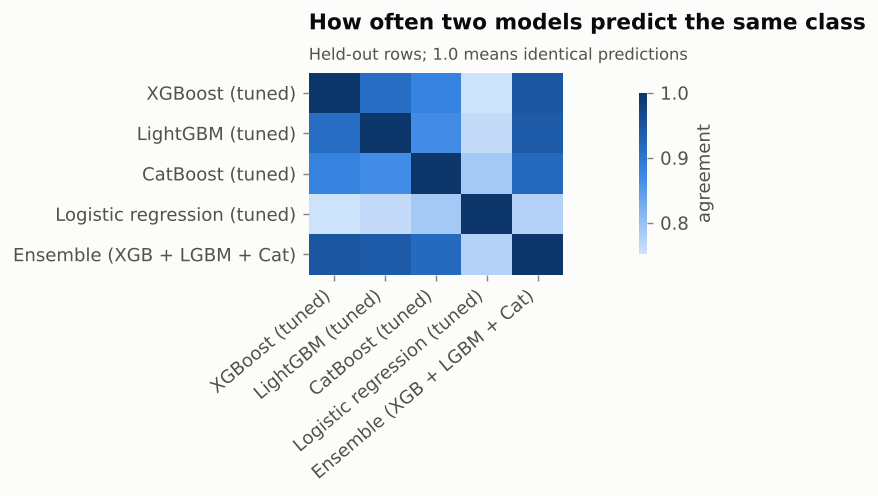

,XGBoost (tuned),LightGBM (tuned),CatBoost (tuned),Logistic regression (tuned),Ensemble (XGB + LGBM + Cat)
XGBoost (tuned),1.000,0.912,0.882,0.752,0.947
LightGBM (tuned),0.912,1.000,0.869,0.760,0.940
CatBoost (tuned),0.882,0.869,1.000,0.787,0.917
Logistic regression (tuned),0.752,0.760,0.787,1.000,0.773
Ensemble (XGB + LGBM + Cat),0.947,0.940,0.917,0.773,1.000


In [5]:
entries = [e for e in ("xgboost_tuned", "lightgbm_tuned", "catboost_tuned", "logreg_tuned", "ensemble") if e in saved.scores.index]
pred = pd.DataFrame({e: saved.proba(e).to_numpy().argmax(axis=1) for e in entries})
agree = pd.DataFrame({a: {b: (pred[a] == pred[b]).mean() for b in entries} for a in entries})
agree = agree.rename(index=viz.label, columns=viz.label)
viz.show(viz.plot_heatmap(agree, "How often two models predict the same class", "Held-out rows; 1.0 means identical predictions", cbar_label="agreement"))
viz.show_table(agree, "Table 4. Share of held-out rows on which two models predict the same class", "{:.3f}")

The tuned models agree on a large share of rows but not all of them, so an ensemble has something to
average; the table above shows how much. That the ensemble still gains nothing in macro-F1 says the
disagreement is mostly noise, not complementary signal.

## 5. Does the minimum-count rule matter?

Raising the minimum number of cases a row needs in its first year removes noisy small counts. If the models
were finding real, large-count trends, the edge over the rule should grow with the threshold.

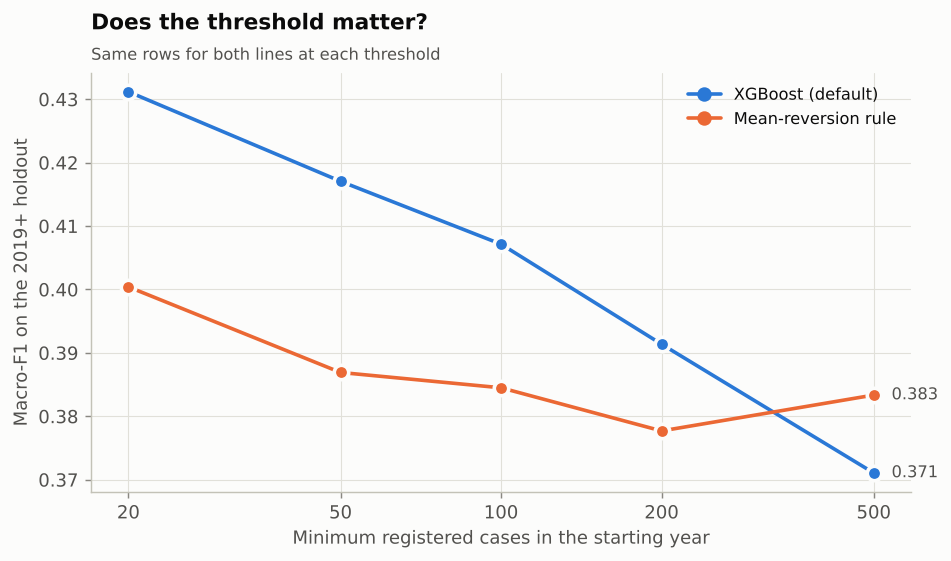

,training rows,test rows,XGBoost F1 (macro),rule F1 (macro),XGBoost ROC-AUC,edge [95% CI]
min_cases,,,,,,
20,"35,564","16,176",0.431,0.400,0.621,"+0.031 [+0.011, +0.047]"
50,"28,126","12,268",0.417,0.387,0.609,"+0.030 [+0.009, +0.051]"
100,"22,919","9,733",0.407,0.384,0.602,"+0.023 [-0.003, +0.047]"
200,"18,611","7,602",0.391,0.378,0.587,"+0.014 [-0.017, +0.045]"
500,"13,078","5,404",0.371,0.383,0.566,"-0.012 [-0.044, +0.023]"


In [6]:
sens = pd.read_csv(cfg.paths.metrics / f"{target}_sensitivity.csv")
viz.show(viz.plot_sensitivity(sens))
table = sens.assign(edge_ci=[f"{r['diff']:+.3f} [{r.diff_lo:+.3f}, {r.diff_hi:+.3f}]" for _, r in sens.iterrows()])[
    ["min_cases", "n_dev", "n_test", "model_f1", "rule_f1", "model_auc", "edge_ci"]
].rename(columns={"n_dev": "training rows", "n_test": "test rows", "model_f1": "XGBoost F1 (macro)",
                  "rule_f1": "rule F1 (macro)", "model_auc": "XGBoost ROC-AUC", "edge_ci": "edge [95% CI]"}).set_index("min_cases")
viz.show_table(
    table,
    "Table 5. Default XGBoost against the mean-reversion rule at each minimum count",
    {"training rows": "{:,}", "test rows": "{:,}", "XGBoost F1 (macro)": "{:.3f}", "rule F1 (macro)": "{:.3f}", "XGBoost ROC-AUC": "{:.3f}"},
)

It does the opposite. The model's edge is clearly positive at 20 and 50 cases, its interval spans zero from
100, and at 500 the point estimate is slightly negative. That is consistent with (though it does not prove)
part of the predictable movement being small counts bouncing back towards their usual level, which a simple
rule also captures. The honest reading is that this task has a modest, partly mechanical signal.

## Conclusion: is XGBoost enough?

**Yes. The limit is the data, not the algorithm.** LightGBM, CatBoost, a logistic regression and an
ensemble were all tried on the same split; none beats XGBoost by a margin that survives a paired test, and
XGBoost itself beats a one-line rule by about 0.02 macro-F1. Reported crime counts change definition between
editions and carry no population denominator, so a better learner has little left to find. More leverage
would come from better data (per-capita rates, a clean treatment of 2020) than from a more complex model.